In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Moneyball: IPL Player Valuation")
print("Week 3 - The Cleaning Sprint")
print("Missing Values and Outlier Detection")

Moneyball: IPL Player Valuation
Week 3 - The Cleaning Sprint
Missing Values and Outlier Detection


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw_df = pd.read_excel('/content/IPL_2008_2026_Merged.xlsx')

df = raw_df.copy()

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 1243
Columns: 31


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,2008-04-18,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,...,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,2008-04-19,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,...,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,2008-04-19,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,...,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,2008-04-20,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,...,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,2008-04-20,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,...,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

print("\nStatistical Summary:")
display(df.describe(include='all').T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   event_name       1243 non-null   object        
 1   season           1243 non-null   object        
 2   match_number     1169 non-null   float64       
 3   date             1243 non-null   datetime64[ns]
 4   city             1243 non-null   object        
 5   venue            1243 non-null   object        
 6   team1            1243 non-null   object        
 7   team2            1243 non-null   object        
 8   toss_winner      1243 non-null   object        
 9   toss_decision    1243 non-null   object        
 10  team1_runs       1243 non-null   int64         
 11  team1_wickets    1243 non-null   int64         
 12  team2_runs       1243 non-null   int64         
 13  team2_wickets    1243 non-null   int64         
 14  winner           12

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
event_name,1243,1,Indian Premier League,1243,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,1243.0,19.0,2013.0,76.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match_number,1169.0,NaN,NaN,NaN,31.9213,1.0,16.0,32.0,47.0,72.0,18.626023
date,1243,NaN,NaN,NaN,2017-08-05 06:29:15.108608,2008-04-18 00:00:00,2012-05-16 12:00:00,2017-05-07 00:00:00,2022-05-09 12:00:00,2026-05-31 00:00:00,NaN
city,1243,38,Mumbai,187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
venue,1243,60,Eden Gardens,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team1,1243,19,Chennai Super Kings,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
team2,1243,19,Mumbai Indians,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
toss_winner,1243,19,Mumbai Indians,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
toss_decision,1243,2,field,825,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': missing_values.values,
    'Missing_Percentage': (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by='Missing_Count',
    ascending=False
)

display(missing_report)

print("Total missing values:", df.isnull().sum().sum())

,Column,Missing_Count,Missing_Percentage
2,match_number,74,5.95
14,winner,25,2.01
18,player_of_match,9,0.72
3,date,0,0.00
4,city,0,0.00
5,venue,0,0.00
0,event_name,0,0.00
6,team1,0,0.00
7,team2,0,0.00
9,toss_decision,0,0.00


Total missing values: 108


In [6]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(10))

Duplicate rows: 0


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players


In [7]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['match_number', 'team1_runs', 'team1_wickets', 'team2_runs', 'team2_wickets', 'win_by_runs', 'win_by_wickets', 'overs_limit', 'balls_per_over']

Categorical Columns:
['event_name', 'season', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result_type', 'player_of_match', 'match_referee', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_type', 'gender', 'team_type', 'team1_players', 'team2_players']


In [8]:
outlier_results = []

for column in numerical_columns:
    values = df[column].dropna()

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    outlier_results.append({
        'Column': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': len(outliers)
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)


,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,match_number,16.0,47.0,31.0,-30.5,93.5,0
1,team1_runs,144.0,189.0,45.0,76.5,256.5,27
2,team1_wickets,4.0,8.0,4.0,-2.0,14.0,0
3,team2_runs,138.0,179.0,41.0,76.5,240.5,29
4,team2_wickets,4.0,8.0,4.0,-2.0,14.0,0
5,win_by_runs,0.0,20.0,20.0,-30.0,50.0,108
6,win_by_wickets,0.0,6.0,6.0,-9.0,15.0,0
7,overs_limit,20.0,20.0,0.0,20.0,20.0,0
8,balls_per_over,6.0,6.0,0.0,6.0,6.0,0


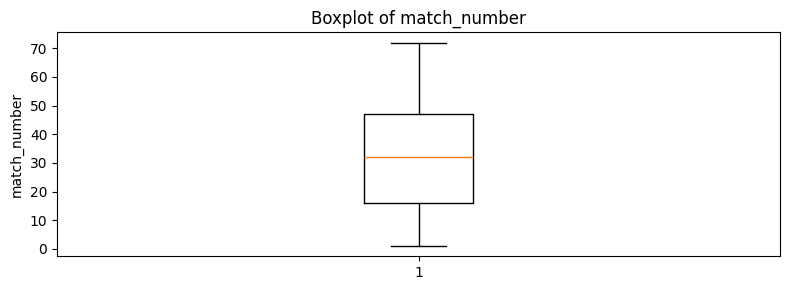

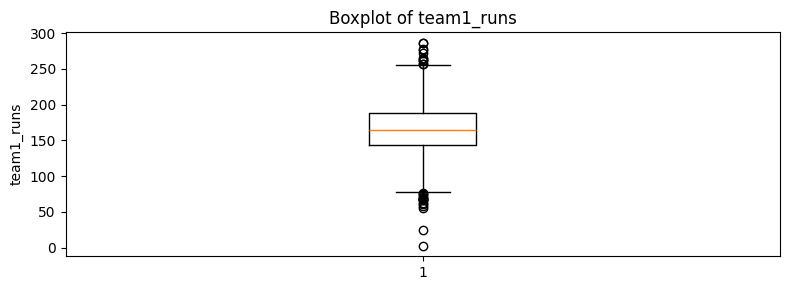

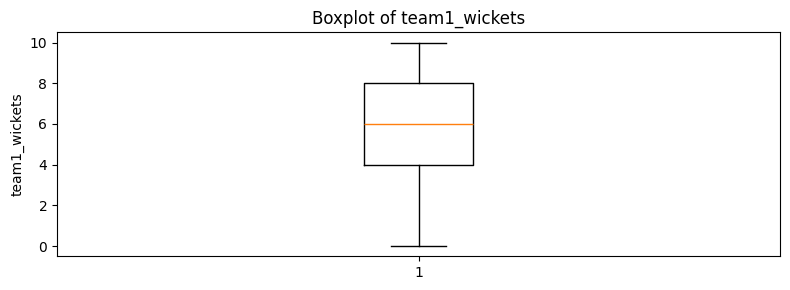

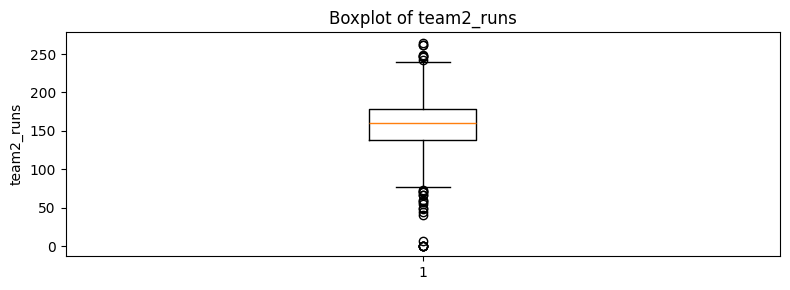

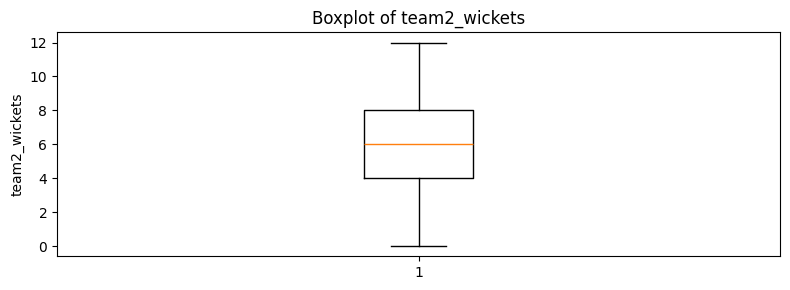

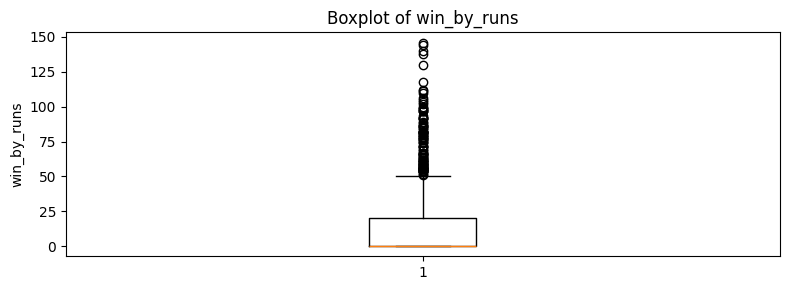

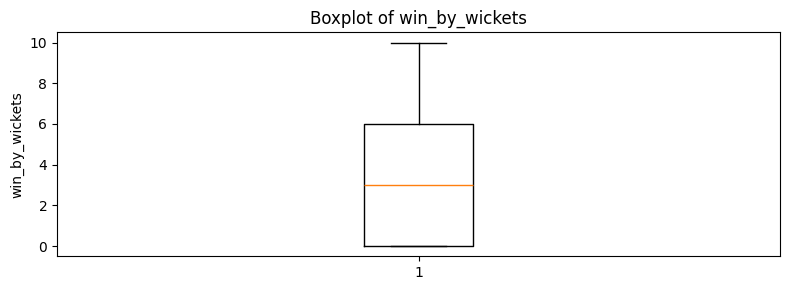

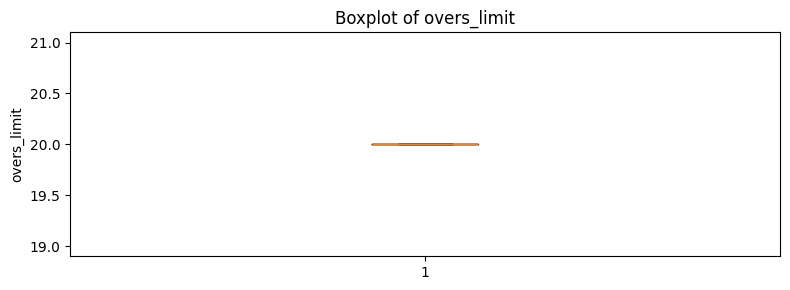

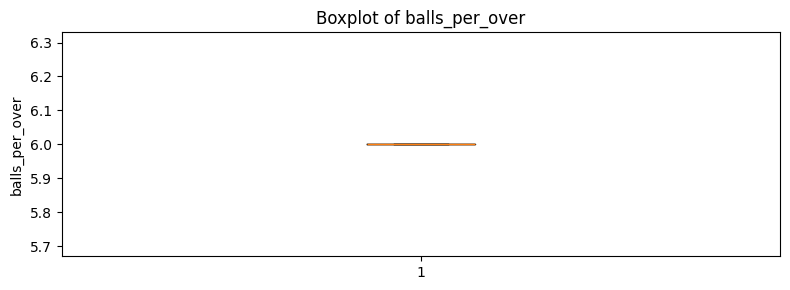

In [9]:
for column in numerical_columns:
    values = df[column].dropna()

    if len(values) == 0:
        continue

    plt.figure(figsize=(8, 3))
    plt.boxplot(values)
    plt.title(f'Boxplot of {column}')
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

In [10]:
print("Checking negative values in numerical columns:")

for column in numerical_columns:
    negative_count = (df[column] < 0).sum()

    if negative_count > 0:
        print(column, ":", negative_count, "negative values")

print("\nChecking unique values in categorical columns:")

for column in categorical_columns:
    print(f"\n{column}:")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False).head(10))

Checking negative values in numerical columns:

Checking unique values in categorical columns:

event_name:
Unique values: 1
event_name
Indian Premier League    1243
Name: count, dtype: int64

season:
Unique values: 19
season
2013       76
2012       74
2026       74
2023       74
2025       74
2022       74
2011       73
2024       71
2014       60
2009/10    60
Name: count, dtype: int64

city:
Unique values: 38
city
Mumbai        187
Kolkata       107
Delhi         104
Chennai        98
Hyderabad      90
Jaipur         68
Bangalore      65
Chandigarh     61
Ahmedabad      53
Pune           51
Name: count, dtype: int64

venue:
Unique values: 60
venue
Eden Gardens                                 77
Wankhede Stadium                             73
M Chinnaswamy Stadium                        65
Feroz Shah Kotla                             60
Wankhede Stadium, Mumbai                     59
Rajiv Gandhi International Stadium, Uppal    49
MA Chidambaram Stadium, Chepauk              48
Sawa

In [11]:
cleaning_df = df.copy()

print("Original dataset shape:", raw_df.shape)
print("Cleaning copy shape:", cleaning_df.shape)

print("\nMissing values in cleaning copy:")
print(cleaning_df.isnull().sum())

print("\nDuplicate rows in cleaning copy:")
print(cleaning_df.duplicated().sum())

Original dataset shape: (1243, 31)
Cleaning copy shape: (1243, 31)

Missing values in cleaning copy:
event_name          0
season              0
match_number       74
date                0
city                0
venue               0
team1               0
team2               0
toss_winner         0
toss_decision       0
team1_runs          0
team1_wickets       0
team2_runs          0
team2_wickets       0
winner             25
result_type         0
win_by_runs         0
win_by_wickets      0
player_of_match     9
match_referee       0
umpire1             0
umpire2             0
tv_umpire           0
reserve_umpire      0
match_type          0
overs_limit         0
balls_per_over      0
gender              0
team_type           0
team1_players       0
team2_players       0
dtype: int64

Duplicate rows in cleaning copy:
0


In [12]:
missing_report.to_csv(
    '/content/Week3_Missing_Values_Report.csv',
    index=False
)

outlier_report.to_csv(
    '/content/Week3_Outlier_Report.csv',
    index=False
)

print("Week 3 reports saved successfully!")

print("1. Week3_Missing_Values_Report.csv")
print("2. Week3_Outlier_Report.csv")

Week 3 reports saved successfully!
1. Week3_Missing_Values_Report.csv
2. Week3_Outlier_Report.csv


In [13]:
cleaning_df.to_csv(
    '/content/Week3_Dataset_Before_Cleaning.csv',
    index=False
)

print("Dataset copy saved successfully!")
print("Shape:", cleaning_df.shape)

Dataset copy saved successfully!
Shape: (1243, 31)


In [14]:
print("=" * 45)
print("WEEK 3 - DATA INSPECTION SUMMARY")
print("=" * 45)

print("Original rows:", raw_df.shape[0])
print("Original columns:", raw_df.shape[1])

print("Total missing values:", raw_df.isnull().sum().sum())
print("Duplicate rows:", raw_df.duplicated().sum())

print(
    "Numerical columns checked:",
    len(numerical_columns)
)

print(
    "Categorical columns checked:",
    len(categorical_columns)
)

if not outlier_report.empty:
    print(
        "Columns with potential outliers:",
        (outlier_report['Outlier_Count'] > 0).sum()
    )

print("\nReports created:")
print("- Week3_Missing_Values_Report.csv")
print("- Week3_Outlier_Report.csv")
print("- Week3_Dataset_Before_Cleaning.csv")

print("\nWeek 3 inspection completed!")

WEEK 3 - DATA INSPECTION SUMMARY
Original rows: 1243
Original columns: 31
Total missing values: 108
Duplicate rows: 0
Numerical columns checked: 9
Categorical columns checked: 21
Columns with potential outliers: 3

Reports created:
- Week3_Missing_Values_Report.csv
- Week3_Outlier_Report.csv
- Week3_Dataset_Before_Cleaning.csv

Week 3 inspection completed!


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw_df = pd.read_csv('/content/IPL_Auction_2008_2026_Combined.csv')

df = raw_df.copy()

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 2700
Columns: 11


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source
0,2008,P0473,MS Dhoni,CSK,NaN,950.0,Wicket-Keeper,Indian,SOLD,auction,manual_2008
1,2008,P0011,Andrew Symonds,DCH,NaN,650.0,All-Rounder,Overseas,SOLD,auction,manual_2008
2,2008,P0709,Sanath Jayasuriya,MI,NaN,575.0,All-Rounder,Overseas,SOLD,auction,manual_2008
3,2008,P0295,Ishant Sharma,KKR,NaN,550.0,Bowler,Indian,SOLD,auction,manual_2008
4,2008,P0207,Mahela Jayawardene,DC,NaN,525.0,Batsman,Overseas,SOLD,auction,manual_2008


In [16]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': missing_values.values,
    'Missing_Percentage': (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by='Missing_Count',
    ascending=False
)

display(missing_report)

print("Total missing values:", df.isnull().sum().sum())

,Column,Missing_Count,Missing_Percentage
4,base_price_lakh,2348,86.96
6,role,1275,47.22
7,nationality,1123,41.59
5,final_price_lakh,303,11.22
1,player_id,72,2.67
2,player_name,0,0.00
0,year,0,0.00
3,team,0,0.00
8,status,0,0.00
9,acquisition_type,0,0.00


Total missing values: 5121


In [17]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

duplicate_rows = df[df.duplicated(keep=False)]

display(duplicate_rows.head(10))

Total duplicate rows: 0


,year,player_id,player_name,team,base_price_lakh,final_price_lakh,role,nationality,status,acquisition_type,source


In [18]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

outlier_results = []

for column in numerical_columns:
    values = df[column].dropna()

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    outlier_results.append({
        'Column': column,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': len(outliers)
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)

,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,year,2001.0,2033.0,0
1,base_price_lakh,-85.0,195.0,19
2,final_price_lakh,-507.5,952.5,181


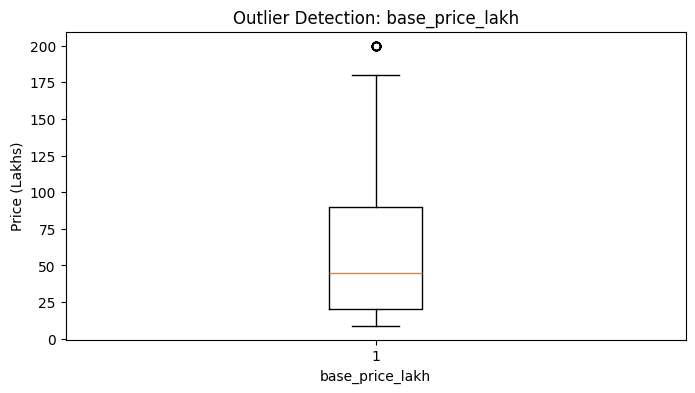

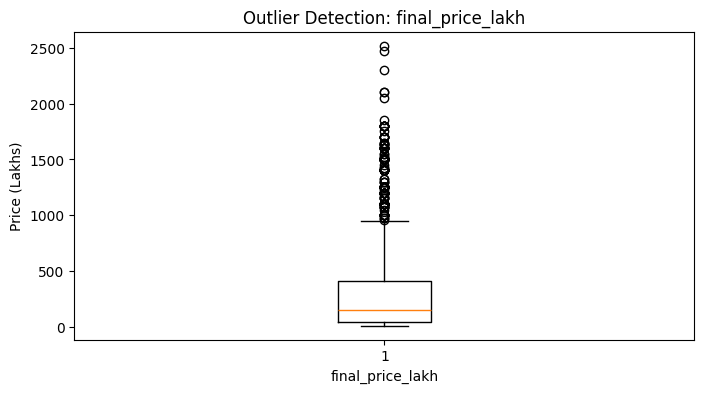

In [19]:
for column in ['base_price_lakh', 'final_price_lakh']:
    if column in df.columns:
        values = df[column].dropna()

        plt.figure(figsize=(8, 4))
        plt.boxplot(values)
        plt.title(f'Outlier Detection: {column}')
        plt.ylabel('Price (Lakhs)')
        plt.xlabel(column)
        plt.show()

In [20]:
print("Checking negative values:")

for column in df.select_dtypes(include=np.number).columns:
    negative_count = (df[column] < 0).sum()

    if negative_count > 0:
        print(column, ":", negative_count)

print("\nCategorical column values:")

for column in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False).head(10))

Checking negative values:

Categorical column values:

Column: player_id
Unique values: 892
player_id
NaN      72
P0622    22
P0464    22
P0834    18
P0866    17
P0625    16
P0473    16
P0463    15
P0236    15
P0574    15
Name: count, dtype: int64

Column: player_name
Unique values: 1129
player_name
MS Dhoni           16
AB de Villiers     14
Harbhajan Singh    13
Jaydev Unadkat     12
V Kohli            11
RG Sharma          11
WP Saha            11
Shakib Al Hasan    10
Sandeep Sharma     10
Yuvraj Singh       10
Name: count, dtype: int64

Column: team
Unique values: 18
team
DC      321
RCB     312
KKR     307
MI      298
PBKS    294
RR      263
CSK     256
SRH     230
DCH      72
-        71
Name: count, dtype: int64

Column: role
Unique values: 6
role
NaN              1275
Bowler            498
All-Rounder       473
Batsman           270
Wicket-Keeper     138
Unknown            33
Batter             13
Name: count, dtype: int64

Column: nationality
Unique values: 2
nationality
NaN 

In [21]:
cleaning_df = df.copy()

print("Original dataset shape:", raw_df.shape)
print("Cleaning copy shape:", cleaning_df.shape)

print("\nOriginal dataset preserved.")
print("Separate cleaning copy created.")

Original dataset shape: (2700, 11)
Cleaning copy shape: (2700, 11)

Original dataset preserved.
Separate cleaning copy created.


In [22]:
missing_report = pd.DataFrame({
    'Column': cleaning_df.columns,
    'Missing_Count': cleaning_df.isnull().sum().values,
    'Missing_Percentage': (
        cleaning_df.isnull().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by='Missing_Count',
    ascending=False
)

display(missing_report)

,Column,Missing_Count,Missing_Percentage
4,base_price_lakh,2348,86.96
6,role,1275,47.22
7,nationality,1123,41.59
5,final_price_lakh,303,11.22
1,player_id,72,2.67
2,player_name,0,0.00
0,year,0,0.00
3,team,0,0.00
8,status,0,0.00
9,acquisition_type,0,0.00


In [23]:
outlier_rows = []

for column in cleaning_df.select_dtypes(include=np.number).columns:
    values = cleaning_df[column].dropna()

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        cleaning_df[column].notna() &
        (
            (cleaning_df[column] < lower_bound) |
            (cleaning_df[column] > upper_bound)
        )
    )

    outlier_rows.append({
        'Column': column,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': int(mask.sum())
    })

outlier_report = pd.DataFrame(outlier_rows)

display(outlier_report)

,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,year,2001.0,2033.0,0
1,base_price_lakh,-85.0,195.0,19
2,final_price_lakh,-507.5,952.5,181


In [24]:
cleaning_decisions = pd.DataFrame({
    'Issue': [
        'Missing base price',
        'Missing final price',
        'Missing player role',
        'Missing nationality',
        'Potential outliers',
        'Exact duplicate rows'
    ],
    'Decision': [
        'Investigate original auction record',
        'Verify auction status and price',
        'Verify reliable player information',
        'Verify reliable player information',
        'Investigate before changing values',
        'No duplicates found in earlier check'
    ]
})

missing_report.to_csv(
    '/content/Week3_Missing_Values_Report.csv',
    index=False
)

outlier_report.to_csv(
    '/content/Week3_Outlier_Report.csv',
    index=False
)

cleaning_decisions.to_csv(
    '/content/Week3_Cleaning_Decisions.csv',
    index=False
)

print("Reports saved successfully!")

Reports saved successfully!


In [25]:
cleaning_df.to_csv(
    '/content/Week3_Dataset_Before_Cleaning.csv',
    index=False
)

print("Dataset saved successfully!")
print("Rows:", cleaning_df.shape[0])
print("Columns:", cleaning_df.shape[1])

Dataset saved successfully!
Rows: 2700
Columns: 11


In [26]:
print("=" * 45)
print("WEEK 3 - CLEANING SPRINT SUMMARY")
print("=" * 45)

print("Original rows:", raw_df.shape[0])
print("Original columns:", raw_df.shape[1])

print("Missing values:", raw_df.isnull().sum().sum())
print("Duplicate rows:", raw_df.duplicated().sum())

print(
    "Numerical columns:",
    len(cleaning_df.select_dtypes(include=np.number).columns)
)

print(
    "Categorical columns:",
    len(cleaning_df.select_dtypes(include='object').columns)
)

print("\nGenerated reports:")
print("1. Week3_Missing_Values_Report.csv")
print("2. Week3_Outlier_Report.csv")
print("3. Week3_Cleaning_Decisions.csv")
print("4. Week3_Dataset_Before_Cleaning.csv")

print("\nWeek 3 inspection completed!")

WEEK 3 - CLEANING SPRINT SUMMARY
Original rows: 2700
Original columns: 11
Missing values: 5121
Duplicate rows: 0
Numerical columns: 3
Categorical columns: 8

Generated reports:
1. Week3_Missing_Values_Report.csv
2. Week3_Outlier_Report.csv
3. Week3_Cleaning_Decisions.csv
4. Week3_Dataset_Before_Cleaning.csv

Week 3 inspection completed!
